In [1]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [18]:
data = np.load(
    "site_16023302_model_data.npz",
    allow_pickle=True

)

print(data.files)

['X_train', 'y_train', 'X_validation', 'y_validation', 'X_test', 'y_test', 'dates_train', 'dates_validation', 'dates_test']


In [3]:
# Load training and validation datasets

X_train = data["X_train"]
y_train = data["y_train"]

X_validation = data["X_validation"]
y_validation = data["y_validation"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_validation shape:", X_validation.shape)
print("y_validation shape:", y_validation.shape)

X_train shape: (296, 14, 1)
y_train shape: (296,)
X_validation shape: (64, 14, 1)
y_validation shape: (64,)


In [4]:
# Build BiLSTM model

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(14, 1)),
    Bidirectional(LSTM(16)),
    Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 32)             │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,337 (9.13 KB)

 Trainable params: 2,337 (9.13 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Compile the model

model.compile(
    optimizer="adam",
    loss="mse"
)

print("Model compiled successfully.")

Model compiled successfully.


In [6]:
# Early stopping to prevent overfitting

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [7]:
# Train the BiLSTM model

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1427 - val_loss: 0.0519
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0292 - val_loss: 0.0207
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0241 - val_loss: 0.0193
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0228 - val_loss: 0.0189
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0222 - val_loss: 0.0182
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0218 - val_loss: 0.0180
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0214 - val_loss: 0.0176
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0210 - val_loss: 0.0173
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0206 - val_loss: 0.0169
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0202 - val_loss: 0.0166
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0198 - val_loss: 0.0163
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

In [8]:
# Check training results

print("Total epochs trained:", len(history.history["loss"]))

print("Final training loss:", history.history["loss"][-1])

print("Best validation loss:", min(history.history["val_loss"]))

Total epochs trained: 100
Final training loss: 0.010214224457740784
Best validation loss: 0.007609839551150799


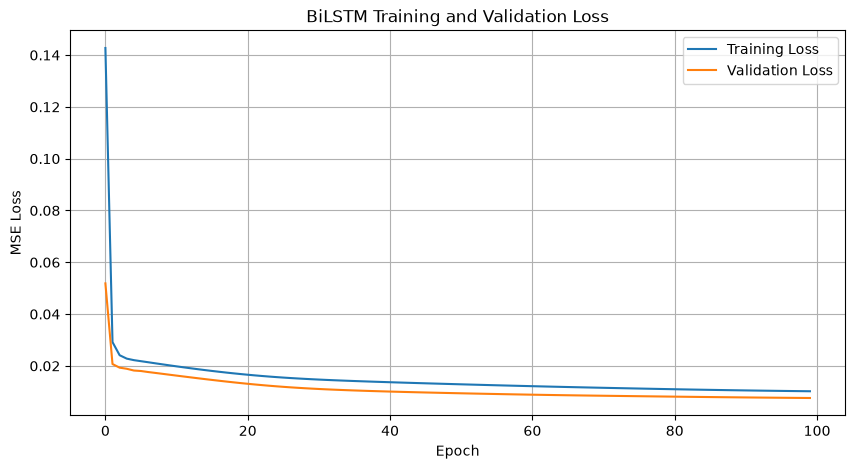

In [12]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("BiLSTM Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.savefig(
    "bilstm_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Save the trained BiLSTM model

model.save("bilstm_soil_moisture.keras")

print("Model saved successfully.")

Model saved successfully.


In [11]:
import pandas as pd

# Save training history

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "bilstm_training_history.csv",
    index=False
)

print("Training history saved successfully.")

Training history saved successfully.


In [13]:
# Load the saved model
from tensorflow.keras.models import load_model

loaded_model = load_model("bilstm_soil_moisture.keras")

# Test prediction using one sample
sample = X_validation[:1]

prediction = loaded_model.predict(sample)

print("Prediction:", prediction)
print("Actual:", y_validation[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
Prediction: [[0.42881995]]
Actual: 0.4158878504672898


In [14]:
# Load the fitted scaler

import joblib

scaler = joblib.load("site_16023302_minmax_scaler.pkl")

print("Scaler loaded successfully.")

Scaler loaded successfully.


/Users/lynn/Desktop/ENGG2112_Project/.venv/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [15]:
# Build persistence baseline

X_test = data["X_test"]
y_test = data["y_test"]

baseline_predictions = X_test[:, -1, 0]

print("X_test shape:", X_test.shape)
print("Baseline predictions shape:", baseline_predictions.shape)

X_test shape: (64, 14, 1)
Baseline predictions shape: (64,)


In [16]:
# Generate BiLSTM predictions on test data

bilstm_predictions = loaded_model.predict(X_test).flatten()

print("BiLSTM predictions shape:", bilstm_predictions.shape)
print("Baseline predictions shape:", baseline_predictions.shape)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  
BiLSTM predictions shape: (64,)
Baseline predictions shape: (64,)


In [19]:
# Convert predictions back to original ASM values

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

bilstm_original = scaler.inverse_transform(
    bilstm_predictions.reshape(-1, 1)
).flatten()

baseline_original = scaler.inverse_transform(
    baseline_predictions.reshape(-1, 1)
).flatten()
# Save test predictions

import pandas as pd

test_results = pd.DataFrame({
    "Date": pd.to_datetime(data["dates_test"]),
    "Actual_ASM": y_test_original,
    "BiLSTM_Prediction": bilstm_original,
    "Persistence_Prediction": baseline_original
})

test_results.to_csv(
    "test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")

display(test_results.head())

Test predictions saved successfully.


,Date,Actual_ASM,BiLSTM_Prediction,Persistence_Prediction
0,2018-04-24,0.189,0.192762,0.207
1,2018-04-25,0.203,0.193273,0.189
2,2018-04-26,0.235,0.200861,0.203
3,2018-04-27,0.210,0.222519,0.235
4,2018-04-28,0.204,0.216035,0.210


## Model Configuration

### Model Architecture
- Model: Bidirectional LSTM (BiLSTM)
- Input: Previous 14 days of ASM
- Input shape: (14, 1)
- BiLSTM units: 16 per direction
- Output layer: Dense(1)
- Total trainable parameters: 2,337

### Training Configuration
- Optimizer: Adam
- Loss function: Mean Squared Error (MSE)
- Maximum epochs: 100
- Batch size: 16
- Early stopping: Enabled
- Early stopping monitor: Validation loss
- Patience: 10
- Restore best weights: True
- Random seed: 42

### Dataset
- Training samples: 296
- Validation samples: 64
- Test samples: 64
- Data normalisation: MinMaxScaler
- Input features: ASM only

### Training Results
- Total epochs trained: 100
- Final training loss: 0.010214
- Best validation loss: 0.007610

### Baseline
- Persistence baseline
- Next-day ASM is predicted using the most recent observed ASM value.